# Introducción

**Proyecto de Ciencia de Datos · Cafetería.** Este notebook incorpora un Análisis Exploratorio de Datos (EDA) sobre `dataset_cafeteria.csv`, la única fuente utilizada, y lo integra con el diagnóstico (Capa 1) y la propuesta (Capa 2) ya desarrollados, que se incluyen completos más adelante.

**Pregunta que guía el EDA:** ¿qué productos y qué momentos concentran las compras, y qué tan confiable es el dato para responderlo?

No incluye modelado: el objetivo es entender el dato y reunir evidencia para las conclusiones del proyecto.

# Carga de librerías

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

# Carga de datos

In [ ]:
# El archivo debe estar en la misma carpeta que el notebook
df = pd.read_csv("dataset_cafeteria.csv")
COLS = list(df.columns)
print(f"{df.shape[0]:,} filas x {df.shape[1]} columnas")

3,898 filas x 6 columnas


# Exploración inicial

Se revisa primero la forma, los tipos de dato y las estadísticas básicas, sin modificar nada.

In [ ]:
df.info()
# Estadísticas descriptivas: numéricas y categóricas
display(df.describe().round(2))
display(df[["date", "datetime", "cash_type", "card", "coffee_name"]].describe().T)

<class 'pandas.DataFrame'>
RangeIndex: 3898 entries, 0 to 3897
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         3898 non-null   str    
 1   datetime     3898 non-null   str    
 2   cash_type    3898 non-null   str    
 3   card         3547 non-null   str    
 4   money        3898 non-null   float64
 5   coffee_name  3898 non-null   str    
dtypes: float64(1), str(5)
memory usage: 362.2 KB


,money
count,3898.00
mean,31.38
std,5.06
min,15.00
25%,27.92
50%,32.82
75%,35.76
max,40.00


,count,unique,top,freq
date,3898,381,2025-02-26,35
datetime,3898,924,10:12,12
cash_type,3898,2,card,3729
card,3547,1316,ANON-0000-0000-0012,129
coffee_name,3898,34,Americano with Milk,824


In [ ]:
df.head()

,date,datetime,cash_type,card,money,coffee_name
0,2024-03-01,10:15,card,ANON-0000-0000-0001,38.7,Latte
1,2024-03-01,12:19,card,ANON-0000-0000-0002,38.7,Hot Chocolate
2,2024-03-01,12:20,card,ANON-0000-0000-0002,38.7,Hot Chocolate
3,2024-03-01,13:46,card,ANON-0000-0000-0003,28.9,Americano
4,2024-03-01,13:48,card,ANON-0000-0000-0004,38.7,Latte


| Columna | Contenido observado |
|---|---|
| `date` | Fecha de la venta (texto, AAAA-MM-DD) |
| `datetime` | Solo la hora de la venta (HH:MM) |
| `cash_type` | Medio de pago: `card` o `cash` |
| `card` | ID anonimizado de tarjeta (nulo en efectivo y en parte de los pagos con tarjeta) |
| `money` | Monto de la venta; el dataset no indica moneda |
| `coffee_name` | Nombre del producto |

Una sola columna es numérica (`money`); el resto son texto, incluidas las de fecha y hora. Cada fila es una venta de un producto: no hay cantidad ni ID de transacción.

### Orden del archivo

In [ ]:
# Marca temporal auxiliar y detección de un posible quiebre en el orden cronológico
df["ts"] = pd.to_datetime(df["date"] + " " + df["datetime"])
corte = (df["ts"].diff() < pd.Timedelta(0)).idxmax()
df["bloque"] = ["A"] * corte + ["B"] * (len(df) - corte)

df["hora"] = df.ts.dt.hour
df["dia_semana"] = df.ts.dt.dayofweek
df["mes"] = df.ts.dt.to_period("M")
df["franja"] = pd.cut(df.hora, bins=[0, 11, 17, 24],
                      labels=["Mañana (hasta 11 h)", "Mediodía-tarde (12-17 h)", "Noche (desde 18 h)"])

print(f"La fecha retrocede en la fila {corte}: {df.loc[corte-1,'date']} -> {df.loc[corte,'date']}")
dias_B = set(df.loc[df.bloque == "B", "date"])
print(f"Días del bloque B que ya figuran en el bloque A: {len(dias_B & set(df.loc[df.bloque == 'A', 'date']))} de {len(dias_B)}")
display(df.groupby("bloque").agg(filas=("money", "size"), desde=("date", "min"), hasta=("date", "max"),
                                 productos=("coffee_name", "nunique")))

La fecha retrocede en la fila 3636: 2025-03-23 -> 2025-02-08
Días del bloque B que ya figuran en el bloque A: 41 de 41


,filas,desde,hasta,productos
bloque,,,,
A,3636,2024-03-01,2025-03-23,8
B,262,2025-02-08,2025-03-23,30


El archivo se ordena por fecha salvo en un punto: a partir de la fila 3636 (**bloque B**) la cronología reinicia en febrero de 2025. A lo largo del notebook se separa el **bloque A** (filas 0 a 3635) del **bloque B**; el diagnóstico completo de esta división está en la Capa 1.

# Calidad de datos

Auditoría breve de las seis dimensiones; el análisis de causas y su impacto se desarrolla en la Capa 1.

### Completitud · valores nulos

In [ ]:
nulos = df[COLS].isna().sum()
display(pd.DataFrame({"nulos": nulos, "% del total": (nulos / len(df) * 100).round(2)}).sort_values("nulos", ascending=False))

# ¿Dónde se concentran los nulos de `card`?
sin_id = df.groupby(["bloque", "cash_type"]).card.agg(filas="size", sin_ID=lambda s: s.isna().sum())
sin_id["% sin ID"] = (sin_id.sin_ID / sin_id.filas * 100).round(1)
display(sin_id)

,nulos,% del total
card,351,9.0
date,0,0.0
datetime,0,0.0
cash_type,0,0.0
money,0,0.0
coffee_name,0,0.0


filas  sin_ID  % sin ID
bloque cash_type                         
A      card        3547       0       0.0
       cash          89      89     100.0
B      card         182     182     100.0
       cash          80      80     100.0

Solo `card` tiene nulos (351). Los 169 de pagos en efectivo son esperables; los 182 restantes son pagos con tarjeta **sin ID y todos pertenecen al bloque B** (el 100 % de sus pagos con tarjeta, frente a 0 % en A). Como la ausencia se explica por variables observadas (medio de pago y bloque), se clasifica preliminarmente como **MAR** en pagos con tarjeta y como ausencia estructural en efectivo.

### Unicidad · duplicados

In [ ]:
dup = df[COLS].duplicated()
dup_all = df[COLS].duplicated(keep=False)
display(pd.DataFrame({"cantidad": [dup.sum(), dup_all.sum()], "% del total": [dup.mean() * 100, dup_all.mean() * 100]},
                     index=["copias de más", "filas involucradas en alguna duplicación"]).round(2))

,cantidad,% del total
copias de más,16,0.41
filas involucradas en alguna duplicación,32,0.82


### Validez, consistencia y actualidad

In [ ]:
patron_card = r"^ANON-\d{4}-\d{4}-\d{4}$"
validez = pd.Series({
    "money <= 0": (df.money <= 0).sum(),
    "fechas no interpretables": pd.to_datetime(df.date, errors="coerce").isna().sum(),
    "horas no interpretables": pd.to_datetime(df.datetime, format="%H:%M", errors="coerce").isna().sum(),
    "ID de tarjeta con formato inválido": (~df.card.dropna().str.match(patron_card)).sum(),
})
display(validez.to_frame("registros"))

print(f"Horario de ventas: {df.hora.min()} h a {df.hora.max()} h")
print(f"Etiquetas de producto: {df.coffee_name.nunique()} | tras normalizar mayúsculas: {df.coffee_name.str.lower().nunique()}")

rango = pd.date_range(df.ts.min().normalize(), df.ts.max().normalize())
faltan = set(rango) - set(df.ts.dt.normalize())
print(f"Rango de fechas: {df.ts.min().date()} a {df.ts.max().date()} | días sin registros: {len(faltan)} de {len(rango)}")

,registros
money <= 0,0
fechas no interpretables,0
horas no interpretables,0
ID de tarjeta con formato inválido,0


Horario de ventas: 6 h a 23 h
Etiquetas de producto: 34 | tras normalizar mayúsculas: 33
Rango de fechas: 2024-03-01 a 2025-03-23 | días sin registros: 7 de 388


| Dimensión | Hallazgo en este dataset |
|---|---|
| **Completitud** | `card`: 351 nulos (9,0 %); 169 esperables (efectivo) y 182 en pagos con tarjeta del bloque B |
| **Exactitud** | No verificable sin fuente externa; `money` no indica moneda y el precio de un mismo producto cambia por períodos (ver EDA) |
| **Consistencia** | 34 etiquetas de producto (33 al normalizar mayúsculas); los bloques A y B usan catálogos distintos |
| **Validez** | Sin `money` ≤ 0, fechas y horas interpretables e ID de tarjeta con formato uniforme |
| **Unicidad** | 16 duplicados exactos (0,41 %), imposibles de validar sin ID de transacción |
| **Actualidad** | 01/03/2024 a 23/03/2025, con 7 días sin registros |

# Análisis exploratorio (EDA)

**Base de análisis:** bloque A, solo pagos con tarjeta. Es la captura más consistente de todo el período: no se usa el bloque B (superpuesto con A y sin ID de tarjeta) ni el efectivo (sin registros entre julio de 2024 y enero de 2025). Las cifras son una lectura preliminar, no totales definitivos.

In [ ]:
base = df[(df.bloque == "A") & (df.cash_type == "card")].copy()
print(f"Filas de la base de análisis: {len(base):,} ({len(base)/len(df):.1%} del archivo)")

Filas de la base de análisis: 3,547 (91.0% del archivo)


### Variables categóricas

In [ ]:
# Productos por bloque (los 12 más frecuentes)
prod_bloque = pd.crosstab(df.coffee_name, df.bloque)
prod_bloque["total"] = prod_bloque.sum(axis=1)
display(prod_bloque.sort_values("total", ascending=False).head(12))

solo_B = set(df.loc[df.bloque == "B", "coffee_name"]) - set(df.loc[df.bloque == "A", "coffee_name"])
print(f"Etiquetas del bloque B que no existen en A: {len(solo_B)} de {df.loc[df.bloque == 'B', 'coffee_name'].nunique()}")

bloque,A,B,total
coffee_name,,,
Americano with Milk,824,0,824
Latte,782,24,806
Americano,578,15,593
Cappuccino,501,16,517
Cortado,292,0,292
Hot Chocolate,282,0,282
Cocoa,243,0,243
Espresso,134,18,152
Americano with milk,0,44,44


Etiquetas del bloque B que no existen en A: 26 de 30


Los dos bloques no describen el mismo catálogo: A usa 8 productos y B 30 etiquetas, 26 de ellas inexistentes en A (incluida `Americano with milk`, variante de `Americano with Milk`). El efectivo aparece en ambos, pero con registros solo en períodos acotados.

### Variables numéricas · `money`

,count,mean,std,min,25%,50%,75%,max
bloque,,,,,,,,
A,3636.0,31.75,4.92,18.12,27.92,32.82,35.76,40.0
B,262.0,26.30,4.25,15.00,25.00,27.00,29.00,33.0


Base de análisis: sesgo = -0.54 | valores fuera de 1,5 x IQR = 0
Variación de money explicada por el producto (eta^2): 86.7%


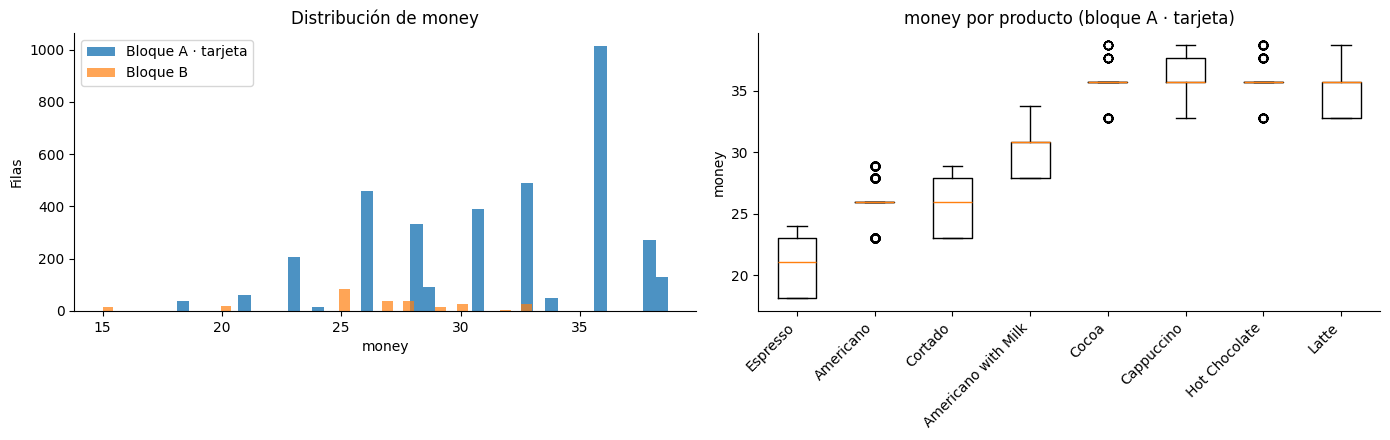

In [ ]:
display(df.groupby("bloque").money.describe().round(2))

q1, q3 = base.money.quantile([.25, .75])
iqr = q3 - q1
fuera = (~base.money.between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)).sum()
print(f"Base de análisis: sesgo = {base.money.skew():.2f} | valores fuera de 1,5 x IQR = {fuera}")

# Proporción de la variación de money explicada por el producto (eta^2)
media_producto = base.groupby("coffee_name").money.transform("mean")
eta2 = ((media_producto - base.money.mean()) ** 2).sum() / ((base.money - base.money.mean()) ** 2).sum()
print(f"Variación de money explicada por el producto (eta^2): {eta2:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(base.money, bins=40, alpha=.8, label="Bloque A · tarjeta")
axes[0].hist(df.loc[df.bloque == "B", "money"], bins=40, alpha=.7, label="Bloque B")
axes[0].set(title="Distribución de money", xlabel="money", ylabel="Filas")
axes[0].legend()

orden = base.groupby("coffee_name").money.median().sort_values().index
axes[1].boxplot([base.loc[base.coffee_name == p, "money"] for p in orden])
axes[1].set_xticklabels(orden, rotation=45, ha="right")
axes[1].set(title="money por producto (bloque A · tarjeta)", ylabel="money")
plt.tight_layout(); plt.show()

`money` no tiene valores atípicos ni cola larga (rango 18,12 a 38,70 en la base de análisis); su forma de varias cimas se explica por el producto, que por sí solo da cuenta de la mayor parte de la variación. Los puntos que aparecen fuera de las cajas por producto no son errores: corresponden a los otros precios que tuvo cada producto en distintos períodos (ver tendencias temporales). El bloque B tiene valores más bajos y redondos (mediana 27,00 frente a 32,82), consistente con un registro distinto.

### Productos · volumen frente a ingresos

In [ ]:
prod = (base.groupby("coffee_name")
            .agg(compras=("money", "size"), ingresos=("money", "sum"), precio_medio=("money", "mean"))
            .sort_values("ingresos", ascending=False))
prod["% compras"] = prod.compras / prod.compras.sum() * 100
prod["% ingresos"] = prod.ingresos / prod.ingresos.sum() * 100
prod["puesto compras"] = prod.compras.rank(ascending=False).astype(int)
prod["puesto ingresos"] = prod.ingresos.rank(ascending=False).astype(int)
prod["% ingresos acum."] = prod["% ingresos"].cumsum()
display(prod.round(1))

rho = prod.compras.corr(prod.ingresos, method="spearman")
print(f"Spearman entre compras e ingresos por producto: {rho:.3f} (n = {len(prod)} productos)")

,compras,ingresos,precio_medio,% compras,% ingresos,puesto compras,puesto ingresos,% ingresos acum.
coffee_name,,,,,,,,
Latte,757,26875.3,35.5,21.3,23.9,2,1,23.9
Americano with Milk,809,24751.1,30.6,22.8,22.1,1,2,46.0
Cappuccino,486,17439.1,35.9,13.7,15.5,4,3,61.5
Americano,564,14650.3,26.0,15.9,13.1,3,4,74.6
Hot Chocolate,276,9933.5,36.0,7.8,8.8,6,5,83.4
Cocoa,239,8521.2,35.7,6.7,7.6,7,6,91.0
Cortado,287,7384.9,25.7,8.1,6.6,5,7,97.6
Espresso,129,2690.3,20.9,3.6,2.4,8,8,100.0


Spearman entre compras e ingresos por producto: 0.881 (n = 8 productos)


Volumen e ingresos van de la mano (Spearman 0,88), pero el orden cambia donde el precio pesa: `Latte` es segundo en compras (21,3 %) y primero en ingresos (23,9 %), mientras `Americano with Milk` lidera en compras (22,8 %) y baja al segundo puesto. Cinco de los ocho productos reúnen el 83,4 % de los ingresos.

### Tendencias temporales

,A · tarjeta,B,días con ventas (A),compras/día (A),ticket medio (A)
mes,,,,,
2024-03,175,0,31,5.6,33.74
2024-04,168,0,30,5.6,34.04
2024-05,241,0,28,8.6,33.88
2024-06,223,0,30,7.4,34.16
2024-07,237,0,31,7.6,29.18
2024-08,272,0,31,8.8,27.99
2024-09,344,0,30,11.5,29.04
2024-10,426,0,31,13.7,32.61
2024-11,259,0,29,8.9,33.17


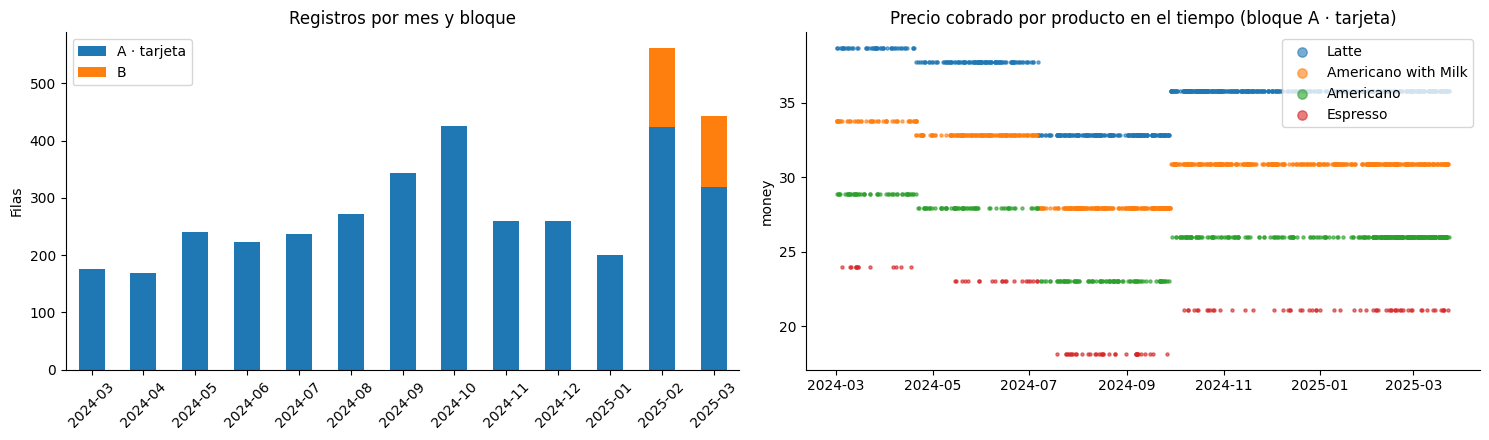

,desde,hasta,compras
money,,,
38.70,2024-03-01,2024-04-19,51
37.72,2024-04-20,2024-07-06,115
32.82,2024-07-06,2024-09-27,194
35.76,2024-09-28,2025-03-23,397


Precios distintos por producto (bloque A · tarjeta): de 4 a 4


In [ ]:
mensual = base.groupby("mes").agg(**{"A · tarjeta": ("money", "size"),
                                      "días con ventas (A)": ("date", "nunique"),
                                      "ticket medio (A)": ("money", "mean")})
mensual.insert(1, "B", df[df.bloque == "B"].groupby("mes").size().reindex(mensual.index, fill_value=0))
mensual.insert(3, "compras/día (A)", mensual["A · tarjeta"] / mensual["días con ventas (A)"])
display(mensual.round({"compras/día (A)": 1, "ticket medio (A)": 2}))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
mensual[["A · tarjeta", "B"]].plot.bar(stacked=True, ax=axes[0])
axes[0].set(title="Registros por mes y bloque", xlabel="", ylabel="Filas")
axes[0].set_xticklabels(mensual.index.astype(str), rotation=45)

for p in ["Latte", "Americano with Milk", "Americano", "Espresso"]:
    x = base[base.coffee_name == p]
    axes[1].scatter(x.ts, x.money, s=5, alpha=.6, label=p)
axes[1].set(title="Precio cobrado por producto en el tiempo (bloque A · tarjeta)", ylabel="money")
axes[1].legend(markerscale=3, loc="upper right")
plt.tight_layout(); plt.show()

# Períodos de vigencia de cada precio de un mismo producto
latte = (base[base.coffee_name == "Latte"].groupby("money")
         .agg(desde=("ts", lambda s: s.min().date()), hasta=("ts", lambda s: s.max().date()), compras=("ts", "size"))
         .sort_values("desde"))
display(latte)
n_precios = base.groupby("coffee_name").money.nunique()
print(f"Precios distintos por producto (bloque A · tarjeta): de {n_precios.min()} a {n_precios.max()}")

- **Volumen:** las compras diarias con tarjeta van de 5,6 (mar-abr 2024) a 15,1 (feb 2025), con picos en octubre de 2024 y febrero de 2025 y sin una tendencia estable. En febrero-marzo de 2025 el bloque B suma 262 filas sobre las 742 de A (+35,3 %), de modo que ese período aparece inflado si se usa el archivo completo.
- **Precios:** cada producto tiene cuatro precios en períodos consecutivos, y los cambios ocurren casi al mismo tiempo en todos (alrededor del 20/04, 06/07 y 28/09 de 2024). `Latte` pasa de 38,70 en marzo a 32,82 entre julio y septiembre y desde fines de septiembre queda en 35,76. El ticket medio refleja esos saltos: 34,16 en junio, 27,99 en agosto y 32,61 en octubre.

### Demanda por hora y día de la semana

,% compras
franja,
Mañana (hasta 11 h),33.3
Mediodía-tarde (12-17 h),40.7
Noche (desde 18 h),26.1


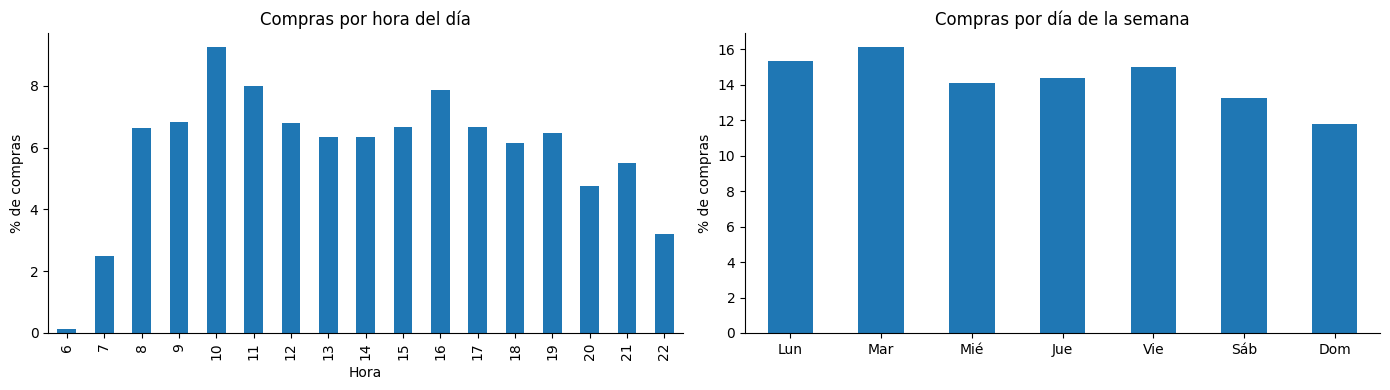

In [ ]:
display((base.franja.value_counts(normalize=True).sort_index() * 100).round(1).to_frame("% compras"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
(base.hora.value_counts(normalize=True).sort_index() * 100).plot.bar(ax=axes[0])
axes[0].set(title="Compras por hora del día", xlabel="Hora", ylabel="% de compras")

por_dia = base.dia_semana.value_counts(normalize=True).sort_index() * 100
por_dia.index = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
por_dia.plot.bar(ax=axes[1], rot=0)
axes[1].set(title="Compras por día de la semana", ylabel="% de compras")
plt.tight_layout(); plt.show()

La demanda se reparte durante todo el día: las horas más fuertes (10, 11 y 16 h) suman solo el 25,1 % y el 26,1 % de las compras ocurre desde las 18 h. Entre días de la semana la variación es baja (11,8 % el domingo a 16,1 % el martes), por lo que el patrón relevante es horario.

### Clientes · compras por tarjeta

In [ ]:
compras_tarjeta = base.card.value_counts()
n10 = int(np.ceil(len(compras_tarjeta) * 0.10))
resumen = pd.Series({
    "tarjetas identificadas": len(compras_tarjeta),
    "% con una sola compra": round((compras_tarjeta == 1).mean() * 100, 1),
    "mediana de compras": compras_tarjeta.median(),
    "media de compras": round(compras_tarjeta.mean(), 2),
    "percentil 90": compras_tarjeta.quantile(.9),
    "máximo": compras_tarjeta.max(),
    "% de compras del 10 % de tarjetas con más compras": round(compras_tarjeta.head(n10).sum() / compras_tarjeta.sum() * 100, 1),
})
display(resumen.to_frame("valor"))

,valor
tarjetas identificadas,1316.0
% con una sola compra,58.6
mediana de compras,1.0
media de compras,2.7
percentil 90,4.0
máximo,129.0
% de compras del 10 % de tarjetas con más compras,50.6


La distribución está muy sesgada a la derecha: la mediana es 1 compra y la media 2,70. El 58,6 % de las tarjetas compró una sola vez, mientras el 10 % con más compras concentra el 50,6 % del total; un único ID acumula 129 compras, algo que debe validarse antes de tratarlo como un cliente.

### Correlaciones relevantes

In [ ]:
dias = (base.ts - base.ts.min()).dt.days
display(base.assign(dias=dias)[["money", "hora", "dia_semana", "dias"]].corr(method="spearman").round(3))

# La hora se relaciona con money a través del mix de productos
display((pd.crosstab(base.franja, base.coffee_name, normalize="index") * 100).round(1))
display(base.groupby("franja", observed=True).money.mean().round(2).to_frame("ticket medio"))

,money,hora,dia_semana,dias
money,1.000,0.209,-0.011,-0.112
hora,0.209,1.000,-0.002,-0.061
dia_semana,-0.011,-0.002,1.000,-0.058
dias,-0.112,-0.061,-0.058,1.000


coffee_name,Americano,Americano with Milk,Cappuccino,Cocoa,Cortado,Espresso,Hot Chocolate,Latte
franja,,,,,,,,
Mañana (hasta 11 h),18.5,28.0,10.3,4.9,12.1,3.7,4.1,18.2
Mediodía-tarde (12-17 h),18.6,20.1,13.7,6.4,6.9,4.6,7.4,22.2
Noche (desde 18 h),8.3,20.3,18.0,9.5,4.8,2.1,13.0,24.0


,ticket medio
franja,
Mañana (hasta 11 h),30.42
Mediodía-tarde (12-17 h),31.75
Noche (desde 18 h),33.04


Las correlaciones son débiles: `money` casi no varía con el día de la semana (-0,01), baja levemente con el paso del tiempo (-0,11, efecto de los cambios de precio) y sube con la hora (0,21). Esto último se explica por el mix: el chocolate caliente pasa de 4,1 % de las compras por la mañana a 13,0 % por la noche, mientras `Cortado` cae de 12,1 % a 4,8 %, y el ticket medio crece de 30,42 a 33,04. El precio depende del producto y del período, no del momento del día.

# Hallazgos principales

| Tema | Hallazgo | Evidencia |
|---|---|---|
| Estructura | El archivo une dos capturas distintas | Fecha retrocede en la fila 3636; B repite 41 días de A y suma +35,3 % de filas en feb-mar 2025 |
| Completitud | Los nulos de `card` están ligados al origen | 351 nulos: 169 en efectivo y 182 pagos con tarjeta, todos en B (100 % de sus pagos con tarjeta) |
| Unicidad | Hay duplicados que no se pueden validar | 16 copias exactas (0,41 %), sin ID de transacción |
| Consistencia | El catálogo no está unificado | 34 etiquetas (33 normalizadas); 26 de las 30 de B no existen en A |
| Precios | El precio de cada producto cambia por períodos | 4 precios por producto (cambios hacia el 20/04, 06/07 y 28/09/2024); el producto explica el 86,7 % de la variación de `money` |
| Productos | Volumen e ingresos están alineados, con matices | Spearman 0,88; `Latte` primero en ingresos y segundo en compras; 3 productos concentran el 60,1 % de las compras |
| Demanda | Se reparte durante el día y el mix cambia | Mañana 33,3 %, mediodía-tarde 40,7 %, noche 26,1 %; chocolate caliente 4,1 % a 13,0 % entre mañana y noche |
| Clientes | Predominan las compras únicas y hay mucha concentración | 58,6 % de las tarjetas compra una vez; el 10 % con más compras explica el 50,6 % |

# Relación con la Capa 1 (Diagnóstico)

El EDA confirma con evidencia cada hallazgo del diagnóstico y no contradice ninguna de sus conclusiones:

| Hallazgo de la Capa 1 | Evidencia en el EDA |
|---|---|
| Captura no estandarizada: dos fuentes unidas | Quiebre de fecha en la fila 3636; B se superpone con 41 días de A y agrega +35,3 % de filas |
| Registro incompleto de clientes | `card` nula solo en B, en el 100 % de sus pagos con tarjeta |
| Sin ID de transacción ni catálogo | 16 duplicados indecidibles; 34 etiquetas de producto y 26 exclusivas de B |
| Precios sin lista que los respalde | Cuatro precios por producto en períodos consecutivos; ticket medio de 34,16 (jun) a 27,99 (ago) |
| Formato deficiente | `datetime` solo contiene la hora; fechas guardadas como texto |

Lo que el EDA agrega es el efecto sobre las métricas: el mismo período cambia más de un tercio según se incluya o no el bloque B, y los ingresos por producto no son comparables en el tiempo sin una lista de precios. El diagnóstico completo se presenta a continuación, sin cambios.

# Etapa 1 - Capa 1: Diagnóstico

Este notebook analiza únicamente el archivo `dataset_cafeteria.csv` (debe estar en la misma carpeta que el notebook). Todas las cifras se calculan en las celdas de código.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)

# Carga del archivo tal cual viene (sin limpiar)
df = pd.read_csv("dataset_cafeteria.csv")

print("Filas x columnas:", df.shape)
display(df.head())
display(df.dtypes.to_frame("tipo"))

Filas x columnas: (3898, 6)


,date,datetime,cash_type,card,money,coffee_name
0,2024-03-01,10:15,card,ANON-0000-0000-0001,38.7,Latte
1,2024-03-01,12:19,card,ANON-0000-0000-0002,38.7,Hot Chocolate
2,2024-03-01,12:20,card,ANON-0000-0000-0002,38.7,Hot Chocolate
3,2024-03-01,13:46,card,ANON-0000-0000-0003,28.9,Americano
4,2024-03-01,13:48,card,ANON-0000-0000-0004,38.7,Latte


,tipo
date,str
datetime,str
cash_type,str
card,str
money,float64
coffee_name,str


## Problema identificado

In [ ]:
# Marca temporal auxiliar (solo para el análisis)
df["ts"] = pd.to_datetime(df["date"] + " " + df["datetime"])

# El archivo está ordenado cronológicamente salvo en un punto: ahí la fecha "retrocede"
corte = (df["ts"].diff() < pd.Timedelta(0)).idxmax()
df["bloque"] = ["A"] * corte + ["B"] * (len(df) - corte)
print(f"La fecha retrocede en la fila {corte}: {df.loc[corte-1,'date']} -> {df.loc[corte,'date']}")

# Comparación de los dos bloques
resumen = df.groupby("bloque").agg(
    filas=("money", "size"),
    desde=("date", "min"),
    hasta=("date", "max"),
    productos_distintos=("coffee_name", "nunique"),
    pct_card_nulo=("card", lambda s: round(s.isna().mean() * 100, 1)),
    ventas_cash=("cash_type", lambda s: (s == "cash").sum()),
)
display(resumen)

# ¿Los bloques cubren los mismos días?
dias_A, dias_B = set(df[df.bloque == "A"].date), set(df[df.bloque == "B"].date)
print("Días del bloque B:", len(dias_B), "| de ellos también presentes en A:", len(dias_A & dias_B))

# Nombres de producto del bloque B que no existen en A
nombres_A = set(df[df.bloque == "A"].coffee_name)
solo_B = df[(df.bloque == "B") & (~df.coffee_name.isin(nombres_A))]
print("Filas de B con productos inexistentes en A:", len(solo_B), f"({len(solo_B)/(df.bloque=='B').sum():.0%} de B)")

# Pagos con tarjeta sin identificador de tarjeta
tarjeta_sin_id = df[(df.cash_type == "card") & (df.card.isna())]
print("Pagos 'card' sin ID de tarjeta:", len(tarjeta_sin_id), "| en bloque B:", (tarjeta_sin_id.bloque == "B").sum())

La fecha retrocede en la fila 3636: 2025-03-23 -> 2025-02-08


,filas,desde,hasta,productos_distintos,pct_card_nulo,ventas_cash
bloque,,,,,,
A,3636,2024-03-01,2025-03-23,8,2.4,89
B,262,2025-02-08,2025-03-23,30,100.0,80


Días del bloque B: 41 | de ellos también presentes en A: 41
Filas de B con productos inexistentes en A: 189 (72% de B)
Pagos 'card' sin ID de tarjeta: 182 | en bloque B: 182


**Problema principal: los datos no tienen una captura única y estandarizada.** El archivo parece la unión de dos fuentes con criterios distintos, y no hay controles que lo garanticen:

- **Bloque A** (3.636 filas, 01/03/2024 – 23/03/2025): 8 productos y tarjeta identificada en todos los pagos con tarjeta.
- **Bloque B** (262 filas, pegadas al final del archivo): reinicia la cronología en el 08/02/2025 y cubre 41 días que **ya están en el bloque A**. Tiene 30 nombres de producto (189 filas con nombres que A no usa) y el **100 % de sus filas sin ID de tarjeta**, incluidos 182 pagos marcados como `card`.
- No existe identificador de transacción, por lo que no se puede saber si las ventas de B duplican las de A o son ventas distintas.

La consecuencia es que hoy **no se puede confiar en el total de ventas, el mix de productos ni el comportamiento de clientes** con este dataset sin una limpieza previa.

## Cultura de datos

Por lo que muestra el archivo, los datos parecen un subproducto del registro de ventas y no un activo que se gestione: no hay catálogo de productos ni lista de precios (el mismo producto aparece con varios precios y nombres), la forma de registrar cambió sin dejar rastro entre el bloque A y el B, y durante siete meses no figura ninguna venta en efectivo. Esto sugiere que las decisiones se toman de manera intuitiva o con la observación diaria del local, y que no hay responsables ni reglas de calidad sobre el dato. Es una inferencia a partir de la evidencia del dataset, no una afirmación sobre la organización.

## Calidad de datos

### Valores nulos

In [ ]:
nulos = pd.DataFrame({"nulos": df[df.columns[:6]].isna().sum(),
                      "% nulos": (df[df.columns[:6]].isna().mean() * 100).round(2)})
display(nulos)

# Nulos de 'card' según medio de pago y bloque (en efectivo es esperable que no haya tarjeta)
display(pd.crosstab([df.cash_type, df.card.isna().rename("card_nula")], df.bloque, margins=True))

,nulos,% nulos
date,0,0.0
datetime,0,0.0
cash_type,0,0.0
card,351,9.0
money,0,0.0
coffee_name,0,0.0


bloque                  A    B   All
cash_type card_nula                 
card      False      3547    0  3547
          True          0  182   182
cash      True         89   80   169
All                  3636  262  3898

Solo `card` tiene nulos: 351 (9,0 %). Los 169 pagos en efectivo no tienen tarjeta, y eso es esperable. Los **182 pagos con tarjeta sin ID** no lo son, y todos están en el bloque B.

### Duplicados

In [ ]:
cols = ["date", "datetime", "cash_type", "card", "money", "coffee_name"]
dup = df[df.duplicated(subset=cols, keep="first")]
print(f"Filas duplicadas exactas: {len(dup)} ({len(dup)/len(df):.2%}) | monto asociado: {dup.money.sum():.2f}")
display(dup.bloque.value_counts().to_frame("duplicados"))
display(df[df.duplicated(subset=cols, keep=False)].sort_values(["date", "datetime"])[cols].head(6))

Filas duplicadas exactas: 16 (0.41%) | monto asociado: 483.12


,duplicados
bloque,
A,14
B,2


,date,datetime,cash_type,card,money,coffee_name
463,2024-05-13,15:31,cash,NaN,29.00,Americano
464,2024-05-13,15:31,cash,NaN,29.00,Americano
922,2024-07-05,22:18,card,ANON-0000-0000-0350,27.92,Americano
923,2024-07-05,22:18,card,ANON-0000-0000-0350,27.92,Americano
1370,2024-08-24,10:18,card,ANON-0000-0000-0544,18.12,Espresso
1371,2024-08-24,10:18,card,ANON-0000-0000-0544,18.12,Espresso


Hay 16 filas idénticas (14 en A y 2 en B). Sin identificador de transacción no se puede distinguir un doble registro de dos compras iguales en el mismo minuto.

### Inconsistencias

In [ ]:
# 1) Nombres de producto: mayúsculas/minúsculas
nombres = df.coffee_name.value_counts()
print("Etiquetas de producto:", nombres.size, "| tras normalizar mayúsculas:", df.coffee_name.str.lower().nunique())
display(df[df.coffee_name.str.lower() == "americano with milk"].groupby(["coffee_name", "bloque"]).agg(
    filas=("money", "size"), precios=("money", lambda s: sorted(s.unique()))))

# 2) Productos con muy pocas ventas
raros = nombres[nombres < 20]
print(f"Productos con menos de 20 registros: {len(raros)} etiquetas, {raros.sum()} filas ({raros.sum()/len(df):.1%})")

# 3) Precios distintos para un mismo producto
precios = df[df.coffee_name.isin(nombres.head(8).index)].groupby("coffee_name").money.agg(
    precios_distintos="nunique", minimo="min", maximo="max")
display(precios)

# 4) Precio de 'Latte' por mes: cambia sin que exista un registro de listas de precio
df["mes"] = df.ts.dt.to_period("M")
display(pd.crosstab(df[df.coffee_name == "Latte"].mes, df[df.coffee_name == "Latte"].money))

Etiquetas de producto: 34 | tras normalizar mayúsculas: 33


,,filas,precios
coffee_name,bloque,,
Americano with Milk,A,824,"[27.92, 30.86, 32.82, 33.8, 34.0, 35.0]"
Americano with milk,B,44,[25.0]


Productos con menos de 20 registros: 24 etiquetas, 124 filas (3.2%)


,precios_distintos,minimo,maximo
coffee_name,,,
Americano,7,23.02,30.0
Americano with Milk,6,27.92,35.0
Cappuccino,7,30.00,40.0
Cocoa,6,32.82,40.0
Cortado,5,23.02,30.0
Espresso,7,18.12,33.0
Hot Chocolate,6,32.82,40.0
Latte,7,32.82,40.0


money,32.82,33.00,35.76,37.72,38.70,39.00,40.00
mes,,,,,,,
2024-03,0,0,0,0,35,0,13
2024-04,0,0,0,11,16,1,3
2024-05,0,0,0,50,0,8,0
2024-06,0,0,0,50,0,0,0
2024-07,52,0,0,4,0,0,0
2024-08,58,0,0,0,0,0,0
2024-09,84,0,10,0,0,0,0
2024-10,0,0,120,0,0,0,0
2024-11,0,0,68,0,0,0,0


mes,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03
cash_type,,,,,,,,,,,,,
card,175,168,241,223,237,272,344,426,259,259,201,510,414
cash,31,28,26,4,0,0,0,0,0,0,0,51,29


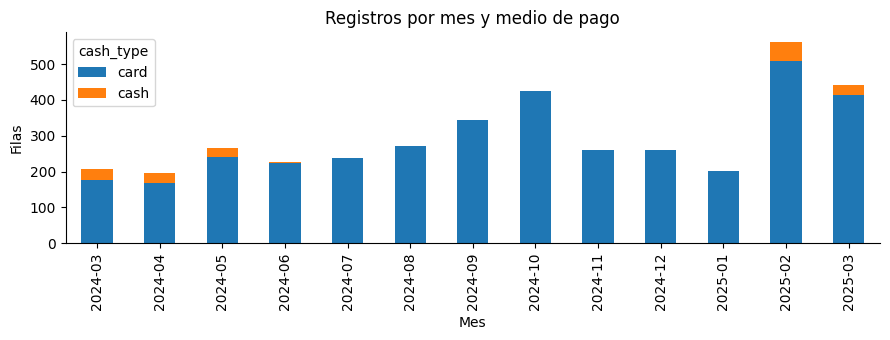

Días sin registros: 7 de 388 -> ['2024-05-01', '2024-05-04', '2024-05-05', '2024-11-27', '2025-01-01', '2025-01-19', '2025-01-23']


In [ ]:
# 5) Registro de efectivo por mes
mensual = pd.crosstab(df.mes, df.cash_type)
display(mensual.T)
mensual.plot(kind="bar", stacked=True, figsize=(9, 3.5), title="Registros por mes y medio de pago")
plt.xlabel("Mes"); plt.ylabel("Filas"); plt.tight_layout(); plt.show()

# 6) Días del rango sin ningún registro
rango = pd.date_range(df.ts.min().normalize(), df.ts.max().normalize())
faltan = sorted(set(rango) - set(df.ts.dt.normalize()))
print(f"Días sin registros: {len(faltan)} de {len(rango)} ->", [d.strftime('%Y-%m-%d') for d in faltan])

- **Nombres:** `Americano with milk` (44 filas, todas en B, siempre a 25,00) es la misma bebida que `Americano with Milk` (824 filas en A, con otros precios). Hay 34 etiquetas, que quedan en 33 al normalizar.
- **Productos marginales:** 24 etiquetas con menos de 20 registros (124 filas), con precios redondos y fijos; todas pertenecen al bloque B.
- **Precios:** el mismo producto toma entre 5 y 7 precios distintos (por ejemplo, `Latte` entre 32,82 y 40,00) y cambia por períodos, sin catálogo que lo respalde.
- **Efectivo:** no hay ventas en efectivo entre julio de 2024 y enero de 2025 (siete meses), y reaparecen en febrero de 2025 solo gracias al bloque B. No sabemos si fue falta de ventas o falta de registro, pero el dato no permite saberlo.
- **Días sin registros:** 7 en 388 días de rango.

### Errores de formato

In [ ]:
# La columna 'datetime' ¿contiene fecha y hora?
print("Longitud de 'datetime':", df.datetime.str.len().unique(), "| ejemplo:", df.datetime.iloc[0])
print("Tipos de date/datetime:", df.date.dtype, "/", df.datetime.dtype)

# Formato del identificador de tarjeta (solo no nulos)
patron = r"^ANON-\d{4}-\d{4}-\d{4}$"
print("IDs de tarjeta con formato válido:", df.card.dropna().str.match(patron).mean().round(3))

# Orden cronológico
print("Retrocesos de fecha en el orden del archivo:", int((df.ts.diff() < pd.Timedelta(0)).sum()))

Longitud de 'datetime': [5] | ejemplo: 10:15
Tipos de date/datetime: str / str
IDs de tarjeta con formato válido: 1.0
Retrocesos de fecha en el orden del archivo: 1


- `datetime` contiene solo la hora (`HH:MM`), no fecha y hora; `date` y `datetime` están guardadas como texto.
- El orden del archivo se rompe en un único punto: el inicio del bloque B.
- El ID de tarjeta, cuando existe, tiene un formato uniforme.

### Otros problemas relevantes

In [ ]:
print("Columnas disponibles:", list(df.columns[:6]))

# Concentración del ID de tarjeta
vc = df.card.value_counts()
print(f"ID más repetido: {vc.index[0]} con {vc.iloc[0]} registros ({vc.iloc[0]/df.card.notna().sum():.1%} de los identificados)")
print(f"Top 10 IDs: {vc.head(10).sum()/df.card.notna().sum():.1%} | IDs con una sola compra: {(vc==1).sum()} de {len(vc)}")

# Variación de volumen en febrero-marzo 2025 por la superposición A+B
display(df.groupby("mes").size().to_frame("filas").T)

Columnas disponibles: ['date', 'datetime', 'cash_type', 'card', 'money', 'coffee_name']
ID más repetido: ANON-0000-0000-0012 con 129 registros (3.6% de los identificados)
Top 10 IDs: 18.7% | IDs con una sola compra: 771 de 1316


mes,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03
filas,206,196,267,227,237,272,344,426,259,259,201,561,443


- **Faltan campos básicos:** no hay ID de transacción, cantidad, moneda, ID de producto ni sucursal/caja; `money` no indica unidad monetaria.
- **ID de tarjeta muy concentrado:** un solo ID acumula 129 registros (3,6 % de los identificados); conviene validar qué representa antes de usarlo como "cliente".
- **Volumen inflado o inconsistente:** febrero de 2025 (561 filas) y marzo (443) superan ampliamente el resto de los meses (rango 196–426), lo que coincide con la superposición de los bloques A y B.

## Stack y Data Warehouse

**Stack actual inferido (a partir del dataset):** un sistema de caja/punto de venta que exporta ventas a un archivo plano (CSV), con unión manual de exportaciones (bloque B pegado al final) y, probablemente, planillas de cálculo para consolidar. No hay evidencia de base de datos, catálogo ni procesos automáticos.

**Limitaciones actuales (con evidencia):**

| Limitación | Evidencia en el dataset |
|---|---|
| Sin esquema ni validaciones | Etiquetas duplicadas por mayúsculas, 5–7 precios por producto |
| Sin trazabilidad de la transacción | Sin ID de venta; 16 duplicados indecidibles |
| Integración manual de fuentes | Bloque B superpuesto con A (41 días), 100 % sin ID de tarjeta |
| Captura incompleta | Sin efectivo julio 2024 – enero 2025; 7 días sin registros |
| Formato pobre | `datetime` solo con hora, fechas como texto |

**Propuesta razonable para una cafetería (a escala pequeña y bajo costo):**

| Capa | Propuesta |
|---|---|
| Origen | POS con API o exportación programada y catálogo de productos/precios maestro |
| Ingesta | Script en Python (o conector tipo Airbyte) que carga cada día a una zona *raw* |
| Data Warehouse | PostgreSQL o BigQuery, con modelo en estrella |
| Modelo | `fact_ventas` (id_transaccion, fecha_hora, id_producto, id_medio_pago, id_cliente_anon, monto, cantidad) y dimensiones `dim_producto`, `dim_tiempo`, `dim_medio_pago`, `dim_cliente` |
| Calidad | Pruebas automáticas (nulos, duplicados, nombres válidos) con dbt o Great Expectations |
| Consumo | Looker Studio o Metabase para tableros |

## Conclusión

El principal problema de la cafetería no es la falta de datos, sino la **falta de una captura estandarizada y confiable**: el dataset combina dos registros con criterios distintos (el bloque B se superpone con 41 días del A, no tiene ID de tarjeta y usa 30 nombres de producto frente a 8), carece de identificador de transacción y catálogo de precios, y muestra huecos como los siete meses sin ventas en efectivo. Mientras esto no se corrija en el origen, cualquier indicador de ventas, productos o clientes será dudoso, por lo que el paso previo a analizar es ordenar la captura y centralizarla en un modelo de datos único.

---
# Relación con la Capa 2 (Propuesta)

El EDA muestra que existen patrones comerciales que justifican el área de analítica propuesta, y que hoy no pueden leerse con confianza:

| Elemento de la Capa 2 | Evidencia en el EDA |
|---|---|
| Demanda por franja horaria | Reparto 33,3 % / 40,7 % / 26,1 % y un mix de productos que cambia entre mañana y noche |
| Rotación de productos | 3 productos concentran el 60,1 % de las compras; `Latte` lidera los ingresos |
| Clientes recurrentes | 58,6 % de las tarjetas compra una sola vez; el 10 % con más compras explica el 50,6 % |
| Priorización (Capa 1 primero) | Precios por períodos, bloque B superpuesto y ausencia de ID de transacción condicionan cada indicador |

La evidencia refuerza el orden ya decidido: primero corregir la captura y después abrir el área. La propuesta completa se presenta a continuación, sin cambios.

---
# Capa 2 · Propuesta

Esta capa parte de los hallazgos de la Capa 1 y usa el mismo dataset.

## Área de datos propuesta

**Analítica comercial (demanda y clientes):** un área que convierta el registro de ventas en indicadores de revisión periódica: demanda por franja horaria, rotación de productos y recurrencia de clientes. Según lo observado en la Capa 1, el dataset no muestra señales de que alguien explote estos datos de manera sistemática: no hay catálogo, ni reglas de calidad, ni una estructura estable de registro.

## Objetivo

Reemplazar decisiones intuitivas por decisiones respaldadas en indicadores, respondiendo tres preguntas concretas: ¿cuándo se concentra la demanda?, ¿qué productos sostienen las ventas? y ¿cuántos clientes vuelven? El objetivo no es fijar cifras definitivas con los datos actuales, sino habilitar este análisis de forma confiable.

## Beneficios esperados

Como muestra de lo que el área podría entregar, se hace una **lectura preliminar sobre el bloque A, solo pagos con tarjeta**: es la captura más consistente de todo el período. Coherente con la Capa 1, no se usan el bloque B ni los pagos en efectivo, y los resultados no deben leerse como cifras definitivas.

In [ ]:
# Bloque A, solo tarjeta (sin efectivo ni bloque B)
a = df[(df.bloque == "A") & (df.cash_type == "card")].copy()
a["hora"] = a.ts.dt.hour
a["franja"] = pd.cut(a.hora, bins=[0, 11, 17, 24],
                     labels=["Mañana (hasta 11 h)", "Mediodía-tarde (12-17 h)", "Noche (desde 18 h)"])
print("Filas analizadas:", len(a))

# 1) Demanda por franja, horas más fuertes y día de la semana
display((a.franja.value_counts(normalize=True).sort_index() * 100).round(1).to_frame("% compras"))
print("Horas más fuertes (% de compras):", (a.hora.value_counts(normalize=True).head(3) * 100).round(1).to_dict())
dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
por_dia = (a.ts.dt.dayofweek.value_counts(normalize=True).sort_index() * 100).round(1)
por_dia.index = dias
display(por_dia.to_frame("% compras").T)

# 2) Concentración de productos
share = a.coffee_name.value_counts(normalize=True) * 100
display(pd.DataFrame({"% compras": share.round(1), "% acumulado": share.cumsum().round(1)}))

# 3) Clientes recurrentes (por ID de tarjeta)
vc = a.card.value_counts()
rec = pd.DataFrame({
    "tarjetas": [(vc >= 2).sum(), (vc == 1).sum()],
    "% tarjetas": [round((vc >= 2).mean() * 100, 1), round((vc == 1).mean() * 100, 1)],
    "% compras": [round(vc[vc >= 2].sum() / vc.sum() * 100, 1), round(vc[vc == 1].sum() / vc.sum() * 100, 1)],
}, index=["Compran 2 o más veces", "Compran una vez"])
display(rec)

Filas analizadas: 3547


,% compras
franja,
Mañana (hasta 11 h),33.3
Mediodía-tarde (12-17 h),40.7
Noche (desde 18 h),26.1


Horas más fuertes (% de compras): {10: 9.2, 11: 8.0, 16: 7.9}


,Lun,Mar,Mié,Jue,Vie,Sáb,Dom
% compras,15.3,16.1,14.1,14.4,15.0,13.3,11.8


,% compras,% acumulado
coffee_name,,
Americano with Milk,22.8,22.8
Latte,21.3,44.1
Americano,15.9,60.1
Cappuccino,13.7,73.8
Cortado,8.1,81.8
Hot Chocolate,7.8,89.6
Cocoa,6.7,96.4
Espresso,3.6,100.0


,tarjetas,% tarjetas,% compras
Compran 2 o más veces,545,41.4,78.3
Compran una vez,771,58.6,21.7


- **Horarios y dotación:** la demanda no depende de un único pico. El 33,3 % de las compras ocurre por la mañana, el 40,7 % entre las 12 y las 17 h y el 26,1 % desde las 18 h; las tres horas más fuertes (10, 11 y 16 h) suman solo el 25,1 %. Los días de la semana son parejos (entre 11,8 % y 16,1 % cada uno), por lo que la variación relevante es horaria. Conocer este reparto permite ajustar turnos y horarios.
- **Carta e insumos:** tres productos concentran el 60,1 % de las compras y cuatro el 73,8 %, mientras que `Espresso` representa el 3,6 %. Esto ayuda a decidir qué asegurar en stock y qué productos revisar.
- **Clientes:** de 1.316 tarjetas identificadas, 545 (41,4 %) compran más de una vez y generan el 78,3 % de las compras identificadas; 771 (58,6 %) compraron una sola vez. Esa diferencia marca a quién retener y dónde hay margen para acciones de fidelización. El ID corresponde a una tarjeta, no necesariamente a una persona, y el ID más repetido (129 registros) debe validarse, como se señaló en la Capa 1.

## Implementación propuesta

Sin sumar herramientas nuevas a lo planteado en la Capa 1:

1. **Base de partida:** cargar el bloque A (tarjeta) en la tabla `fact_ventas` y sus dimensiones propuestas (`dim_producto`, `dim_tiempo`, `dim_medio_pago`, `dim_cliente`).
2. **Tablero mensual** en Looker Studio o Metabase con cuatro indicadores: compras por franja horaria, ranking de productos, clientes recurrentes frente a únicos y compras por medio de pago.
3. **Responsable:** una persona del equipo que revise el tablero una vez al mes y deje asentadas las decisiones tomadas a partir de él.
4. **Requisitos previos** (vienen de la Capa 1): ID de transacción, catálogo único de productos y registro completo de clientes y medios de pago.

## Relación con la Capa 1

La propuesta surge de dos hallazgos del diagnóstico: los datos existen (3.898 registros en 13 meses) pero parecen un subproducto del registro de ventas, sin uso sistemático; y los problemas de captura detectados son justamente los que condicionan cada indicador de esta área:

| Indicador de la Capa 2 | Dato que necesita | Estado según la Capa 1 |
|---|---|---|
| Demanda por franja horaria | Fecha y hora estandarizadas | `datetime` solo contiene la hora; orden roto en 1 punto |
| Ranking de productos | Catálogo único de productos | 34 etiquetas (33 al normalizar); 24 con menos de 20 registros |
| Clientes recurrentes | ID de cliente completo | 182 pagos `card` sin ID, todos en el bloque B |
| Ingresos por producto | Precio vigente por producto | Entre 5 y 7 precios por producto |
| Ventas por período | ID de transacción | Sin ID; bloque B superpuesto con 41 días del A |

La Capa 2 no corrige estos problemas: depende de que se corrijan.

## Priorización

In [ ]:
# Efecto del bloque B en los días en que coincide con el bloque A
dias_sup = df[df.bloque == "B"].date.unique()
sup = df[df.date.isin(dias_sup)].groupby("bloque").agg(filas=("money", "size"), money=("money", "sum")).round(2)
display(sup)
print(f"En esos {len(dias_sup)} días, B agrega {sup.loc['B','filas']/sup.loc['A','filas']:.1%} de filas "
      f"y {sup.loc['B','money']/sup.loc['A','money']:.1%} en money respecto de A")

,filas,money
bloque,,
A,595,18577.3
B,262,6890.0


En esos 41 días, B agrega 44.0% de filas y 37.1% en money respecto de A


**Decisión: se aborda primero la Capa 1 (diagnóstico y corrección de la captura), y la Capa 2 se habilita después.** La Capa 2 es la que aporta valor al negocio, pero es la Capa 1 la que permite que ese valor sea confiable:

- **Cultura de datos:** la Capa 1 infirió que el dato es un subproducto del registro y que las decisiones parecen intuitivas, sin responsables ni reglas. Un área de analítica sin ese cimiento corre el riesgo de producir tableros que nadie revisa o en los que nadie confía. Primero hay que definir quién es responsable del dato y cómo se registra.
- **Calidad de datos:** en los 41 días en que los bloques A y B coinciden, el bloque B agrega 262 filas (+44,0 %) y 6.890 en `money` (+37,1 %) sobre lo registrado en A. Sin ID de transacción no se sabe si corresponde sumarlas o descartarlas, de modo que cualquier indicador de ese período cambiaría en más de un tercio según una decisión que hoy no está tomada.
- **Stack y Data Warehouse:** la Capa 2 necesita `fact_ventas` y sus dimensiones, y hoy solo existe un archivo plano con unión manual de exportaciones. No hay dónde apoyar los indicadores de forma repetible.

Una vez resueltos el ID de transacción, el catálogo y la integración de fuentes, la Capa 2 puede arrancar con un piloto como la lectura preliminar de arriba.

---
# Conclusiones

El EDA muestra que el dataset contiene patrones comerciales utilizables —una demanda repartida a lo largo del día con un mix de productos que cambia por franja, tres productos que concentran el 60,1 % de las compras y un 58,6 % de tarjetas que compra una sola vez—, pero que hoy no pueden leerse con confianza: el archivo une dos capturas con criterios distintos, el precio de cada producto cambia por períodos sin registro y no existe un identificador de transacción. Por eso se mantiene lo decidido en las capas anteriores: primero ordenar la captura de datos (Capa 1) y recién después abrir el área de analítica comercial (Capa 2), para la cual esta exploración queda como línea de base.